# PathSnap · Team 111 — Data processing & feature engineering (Stages 2–4)

This notebook is the team's deliverable for **data processing** and **feature engineering**.
It covers, in order:

1. Dataset inventory (per partition)
2. Data-quality checks
3. Large time gaps
4. Broken reference routes
5. Road-network connectivity
6. Coordinate projection (choice + validation)
7. Cleaning
8. Labelling rule: reference route → one label per GPS point (incl. trips 33 and 54)
9. Candidate generation: strategy comparison and candidate miss rate
10. Direction twins (two-way roads)
11. Feature engineering (22 features) with evidence for each group
12. Group-aware folds
13. Saved outputs
14. Data-quality decision log
15. Folium maps

**Partitions used:** `train` (80 trips) and `student_test` (10 trips). The `evaluator_test`
partition is never read in this notebook.

The processing code lives in `src/pathsnap/` (`data.py`, `labels.py`, `features.py`) and is the
exact code the API runs at inference time; this notebook calls it, measures it and justifies it.
Run from the repository root or the `notebooks/` folder.

In [1]:
import os, sys, json, time, warnings
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
warnings.filterwarnings("ignore")

ROOT = os.path.abspath(".")
if not os.path.isdir(os.path.join(ROOT, "src")):
    ROOT = os.path.abspath("..")
sys.path.insert(0, os.path.join(ROOT, "src"))
from pathsnap.data import (load_trip, load_route, list_trips, trip_files, gps_heading_speed,
                           angle_diff, EARTH_R)
from pathsnap.labels import align_route
from pathsnap.features import build_features, attach_labels, FEATURES, DEFAULT_CAND

RAW = os.path.join(ROOT, "data", "raw")
PROC = os.path.join(ROOT, "data", "processed"); os.makedirs(PROC, exist_ok=True)
RES = os.path.join(ROOT, "results"); os.makedirs(RES, exist_ok=True)
FIG = os.path.join(ROOT, "figures"); os.makedirs(FIG, exist_ok=True)
MAPS = os.path.join(ROOT, "maps"); os.makedirs(MAPS, exist_ok=True)
PARTS = ["train", "student_test"]
SEED = 111
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("project root:", ROOT)

project root: /home/claude/pathsnap-team111


## 1. Dataset inventory
Every trip folder holds four whitespace-separated files without headers:
`.track` (lon, lat, t), `.nodes` (lon, lat; row = node id), `.arcs` (from, to; row = arc id),
`.route` (ordered arc ids). We read the raw files directly (not through our loader) so that the
inventory reflects the data exactly as delivered.

In [2]:
inv_rows = []
raw_tracks = {}
for part in PARTS:
    for tid in list_trips(os.path.join(RAW, part)):
        f = trip_files(os.path.join(RAW, part, tid))
        tr = pd.read_csv(f["track"], sep=r"\s+", header=None, names=["lon", "lat", "t"])
        nodes = pd.read_csv(f["nodes"], sep=r"\s+", header=None, names=["lon", "lat"])
        arcs = pd.read_csv(f["arcs"], sep=r"\s+", header=None, names=["u", "v"])
        route = np.loadtxt(f["route"], dtype=int, ndmin=1)
        raw_tracks[(part, tid)] = (tr, nodes, arcs, route)
        dt = np.diff(tr.t.values)
        lat0 = np.radians(tr.lat.mean())
        ext_x = np.radians(tr.lon.max() - tr.lon.min()) * EARTH_R * np.cos(lat0) / 1000
        ext_y = np.radians(tr.lat.max() - tr.lat.min()) * EARTH_R / 1000
        inv_rows.append(dict(
            partition=part, trip=tid, files_present=sum(os.path.exists(p) for p in f.values()),
            size_kb=sum(os.path.getsize(p) for p in f.values()) / 1024,
            gps_points=len(tr), nodes=len(nodes), arcs=len(arcs), route_arcs=len(route),
            duration_min=(tr.t.iloc[-1] - tr.t.iloc[0]) / 60,
            pct_1s_steps=100 * (dt == 1).mean(), gaps_gt5s=int((dt > 5).sum()), max_gap_s=dt.max(),
            extent_km=max(ext_x, ext_y), lat_center=tr.lat.mean(), lon_center=tr.lon.mean()))
inv = pd.DataFrame(inv_rows)
inv.to_csv(os.path.join(RES, "stage2_inventory.csv"), index=False)
summary = inv.groupby("partition").agg(
    trips=("trip", "size"), gps_points=("gps_points", "sum"), median_points=("gps_points", "median"),
    min_points=("gps_points", "min"), max_points=("gps_points", "max"),
    median_nodes=("nodes", "median"), median_arcs=("arcs", "median"),
    median_route_arcs=("route_arcs", "median"), median_extent_km=("extent_km", "median"),
    total_mb=("size_kb", lambda s: s.sum() / 1024)).round(1)
summary

,trips,gps_points,median_points,min_points,max_points,median_nodes,median_arcs,median_route_arcs,median_extent_km,total_mb
partition,,,,,,,,,,
student_test,10,19160,1420.0,262,3958,6596.5,13145.0,250.0,6.4,4.2
train,80,208417,1529.0,361,19313,9608.0,19526.5,280.0,8.6,85.6


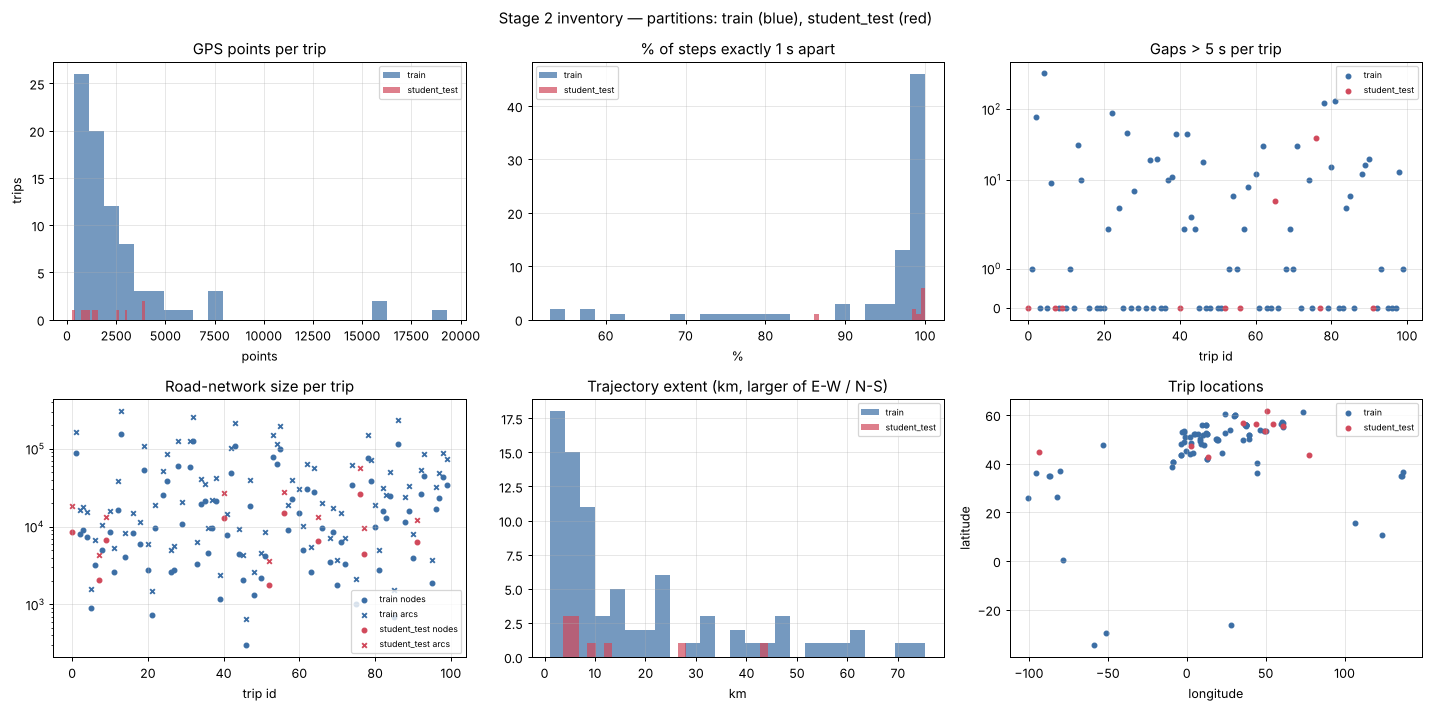

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for part, c in [("train", "#3b6ea5"), ("student_test", "#d1495b")]:
    s = inv[inv.partition == part]
    ax[0, 0].hist(s.gps_points, bins=25, alpha=.7, color=c, label=part)
    ax[0, 1].hist(s.pct_1s_steps, bins=25, alpha=.7, color=c, label=part)
    ax[0, 2].scatter(s.trip.astype(int), s.gaps_gt5s, color=c, s=14, label=part)
    ax[1, 0].scatter(s.trip.astype(int), s.nodes, color=c, s=14, marker="o", label=f"{part} nodes")
    ax[1, 0].scatter(s.trip.astype(int), s.arcs, color=c, s=14, marker="x", label=f"{part} arcs")
    ax[1, 1].hist(s.extent_km, bins=25, alpha=.7, color=c, label=part)
    ax[1, 2].scatter(s.lon_center, s.lat_center, color=c, s=14, label=part)
ax[0, 0].set(title="GPS points per trip", xlabel="points", ylabel="trips")
ax[0, 1].set(title="% of steps exactly 1 s apart", xlabel="%")
ax[0, 2].set(title="Gaps > 5 s per trip", xlabel="trip id", yscale="symlog")
ax[1, 0].set(title="Road-network size per trip", xlabel="trip id", yscale="log")
ax[1, 1].set(title="Trajectory extent (km, larger of E-W / N-S)", xlabel="km")
ax[1, 2].set(title="Trip locations", xlabel="longitude", ylabel="latitude")
for a in ax.ravel():
    a.legend(fontsize=7); a.grid(alpha=.3)
plt.suptitle("Stage 2 inventory — partitions: train (blue), student_test (red)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "stage2_inventory.png"), dpi=120); plt.show()

## 2. Data-quality checks (both partitions)

In [4]:
dq_rows = []
for (part, tid), (tr, nodes, arcs, route) in raw_tracks.items():
    dt = np.diff(tr.t.values)
    rc = (arcs.v.values[route[:-1]] == arcs.u.values[route[1:]]) if len(route) > 1 else np.array([True])
    dq_rows.append(dict(
        partition=part, trip=tid,
        missing_values=int(tr.isna().sum().sum() + nodes.isna().sum().sum() + arcs.isna().sum().sum()),
        invalid_gps_coords=int(((tr.lon.abs() > 180) | (tr.lat.abs() > 90)).sum()),
        invalid_node_coords=int(((nodes.lon.abs() > 180) | (nodes.lat.abs() > 90)).sum()),
        non_increasing_timestamps=int((dt <= 0).sum()),
        duplicate_consecutive_gps=int(((tr.lon.diff() == 0) & (tr.lat.diff() == 0)).sum()),
        arc_refs_valid=bool(arcs.values.max() < len(nodes) and arcs.values.min() >= 0),
        route_refs_valid=bool(route.max() < len(arcs) and route.min() >= 0),
        self_loop_arcs=int((arcs.u == arcs.v).sum()),
        route_breaks=int((~rc).sum()),
        route_connected_pct=100 * rc.mean()))
dq = pd.DataFrame(dq_rows)
dq.to_csv(os.path.join(RES, "stage2_data_quality_report.csv"), index=False)
print(dq.groupby("partition")[["missing_values", "invalid_gps_coords", "invalid_node_coords",
                               "non_increasing_timestamps", "duplicate_consecutive_gps",
                               "self_loop_arcs", "route_breaks"]].sum().to_string())
print("\nall arc references valid:", dq.arc_refs_valid.all(), "| all route references valid:", dq.route_refs_valid.all())
print("trips with a broken reference route:", (dq.route_breaks > 0).sum())

              missing_values  invalid_gps_coords  invalid_node_coords  non_increasing_timestamps  duplicate_consecutive_gps  self_loop_arcs  route_breaks
partition                                                                                                                                                
student_test               0                   0                    0                          0                          0               2             1
train                      0                   0                    0                          0                          6              22            13

all arc references valid: True | all route references valid: True
trips with a broken reference route: 11


**Finding:** no missing values, no invalid coordinates, no non-increasing timestamps and all
references are valid. The real issues are (a) long time gaps, (b) broken reference routes and
(c) unreliable reference labels for a few trips — investigated next. Repeated identical GPS
fixes (vehicle stopped) are kept: they are real observations and the heading feature is
protected against them (section 11).

## 3. Large time gaps

In [5]:
gap_rows = []
for (part, tid), (tr, *_rest) in raw_tracks.items():
    dt = np.diff(tr.t.values)
    for i in np.flatnonzero(dt > 60):
        a = np.radians(tr[["lat", "lon"]].values[[i, i + 1]])
        dlat, dlon = a[1] - a[0]
        hv = 2 * EARTH_R * np.arcsin(np.sqrt(np.sin(dlat / 2) ** 2 + np.cos(a[0, 0]) * np.cos(a[1, 0]) * np.sin(dlon / 2) ** 2))
        gap_rows.append(dict(partition=part, trip=tid, at_index=i, gap_s=dt[i], gap_h=dt[i] / 3600,
                             jump_m=hv, implied_speed_ms=hv / dt[i]))
gaps = pd.DataFrame(gap_rows).sort_values("gap_s", ascending=False)
gaps.to_csv(os.path.join(RES, "stage2_large_gaps.csv"), index=False)
print(f"{len(gaps)} gaps longer than 60 s in {gaps.trip.nunique()} trips")
gaps.head(10).round(1)

70 gaps longer than 60 s in 23 trips


,partition,trip,at_index,gap_s,gap_h,jump_m,implied_speed_ms
68,train,00000090,534,153064.0,42.5,3.3,0.0
43,train,00000078,1,52810.0,14.7,2.5,0.0
41,train,00000069,985,2658.0,0.7,14.4,0.0
11,train,00000021,7868,2161.0,0.6,10.1,0.0
8,train,00000011,1600,909.0,0.3,13.2,0.0
40,train,00000069,843,816.0,0.2,66.2,0.1
23,train,00000042,1891,670.0,0.2,1.1,0.0
10,train,00000021,183,660.0,0.2,19.8,0.0
32,train,00000042,7250,585.0,0.2,12.7,0.0
58,train,00000081,2776,536.0,0.1,5.7,0.0


The two extreme gaps (train trips 90 and 78, about 42 h and 15 h) are pauses: the position
barely moves across the gap (small `jump_m`), i.e. the vehicle was parked and recording
resumed. **Decision:** keep the trips whole. Matching is per observation, and the HMM
transition (stage 7) relaxes with the time gap and widens its path search with the distance
moved, so a pause does not break decoding. Splitting would only add artificial trip starts.

## 4. Broken reference routes

In [6]:
brk_rows = []
for (part, tid), (tr, nodes, arcs, route) in raw_tracks.items():
    for k in np.flatnonzero(arcs.v.values[route[:-1]] != arcs.u.values[route[1:]]):
        a_end = nodes.values[arcs.v.values[route[k]]]; b_start = nodes.values[arcs.u.values[route[k + 1]]]
        lat0 = np.radians(a_end[1])
        d = np.hypot(np.radians(b_start[0] - a_end[0]) * np.cos(lat0), np.radians(b_start[1] - a_end[1])) * EARTH_R
        brk_rows.append(dict(partition=part, trip=tid, route_pos=k, arc_before=route[k], arc_after=route[k + 1],
                             gap_between_arcs_m=d, lon=a_end[0], lat=a_end[1]))
breaks = pd.DataFrame(brk_rows)
breaks.to_csv(os.path.join(RES, "stage2_route_breaks.csv"), index=False)
print(f"{len(breaks)} breaks in {breaks.trip.nunique()} trips; gap between consecutive route arcs (m):")
print(breaks.gap_between_arcs_m.describe().round(1).to_string())
breaks.groupby(["partition", "trip"]).agg(breaks=("route_pos", "size"), max_gap_m=("gap_between_arcs_m", "max")).round(1)

14 breaks in 11 trips; gap between consecutive route arcs (m):
count     14.0
mean     140.8
std      163.7
min       10.6
25%       33.3
50%       82.5
75%      207.7
max      595.8


breaks  max_gap_m
partition    trip                       
student_test 00000076       1       15.0
train        00000002       1      324.7
             00000019       3      595.8
             00000033       1       91.9
             00000041       1       57.2
             00000042       1       30.7
             00000069       1       40.9
             00000075       2       73.0
             00000080       1      107.8
             00000086       1       97.7
             00000089       1       29.3

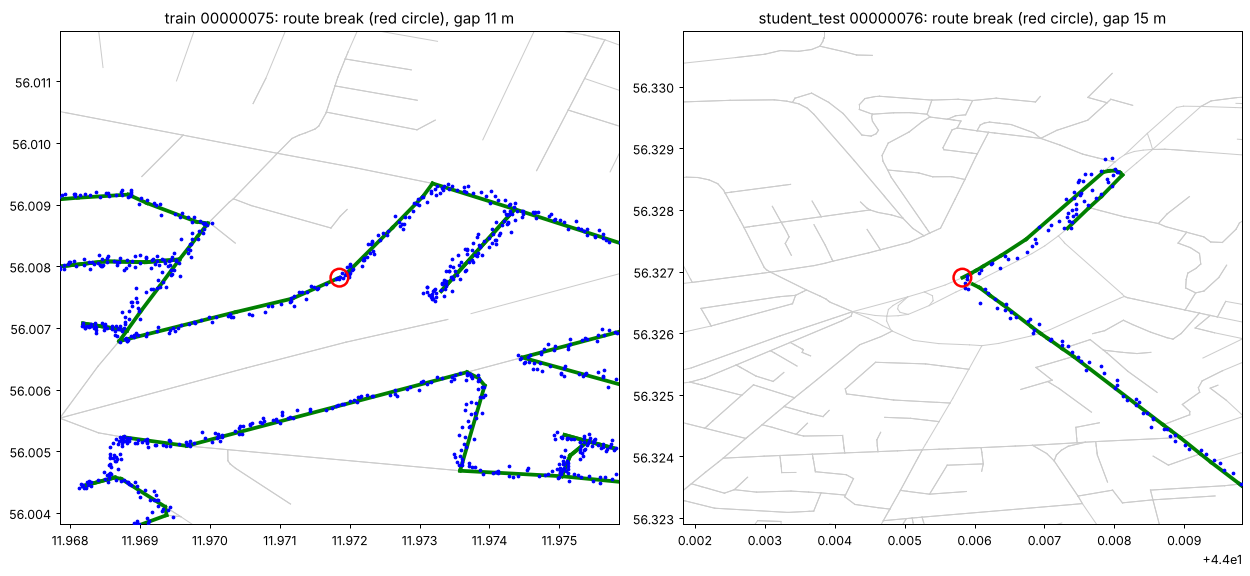

In [7]:
def plot_break(part, tid, ax, pad=0.004):
    tr, nodes, arcs, route = raw_tracks[(part, tid)]
    b = breaks[(breaks.partition == part) & (breaks.trip == tid)].iloc[0]
    lo, hi = np.array([b.lon - pad, b.lat - pad]), np.array([b.lon + pad, b.lat + pad])
    nl = nodes.values
    a0 = nl[arcs.u.values]; a1 = nl[arcs.v.values]
    near = np.flatnonzero(((a0 >= lo) & (a0 <= hi)).all(1))
    for e in near:
        ax.plot([a0[e, 0], a1[e, 0]], [a0[e, 1], a1[e, 1]], color="#cccccc", lw=.8)
    for e in route:
        ax.plot([a0[e, 0], a1[e, 0]], [a0[e, 1], a1[e, 1]], color="green", lw=3)
    ax.scatter(tr.lon, tr.lat, s=4, c="blue", zorder=3)
    ax.scatter([b.lon], [b.lat], s=200, facecolors="none", edgecolors="red", lw=2, zorder=4)
    ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]),
           title=f"{part} {tid}: route break (red circle), gap {b.gap_between_arcs_m:.0f} m")


fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
plot_break("train", "00000075", ax[0]); plot_break("student_test", "00000076", ax[1])
plt.tight_layout(); plt.savefig(os.path.join(FIG, "stage2_route_breaks.png"), dpi=120); plt.show()

**What the breaks are:** consecutive reference arcs whose end and start nodes differ, usually by
a short distance — the reference skips a short link (e.g. a junction connector or a missing
segment). The GPS track is continuous across the break, so it is a limitation of the
*reference*, not of the vehicle's movement. **Decision:** keep these trips. Our labelling rule
(section 8) assigns each GPS point to the nearest route arc in route order, so a break only
affects the few points right at the break. We report the reference's own continuity next to
ours so route-continuity results are not overstated.

## 5. Road-network connectivity

In [8]:
net_rows = []
for (part, tid), (tr, nodes, arcs, route) in raw_tracks.items():
    G = nx.DiGraph(); G.add_nodes_from(range(len(nodes))); G.add_edges_from(arcs.values.tolist())
    wcc = sorted(nx.weakly_connected_components(G), key=len, reverse=True)
    biggest = wcc[0]
    rnodes = set(arcs.u.values[route]) | set(arcs.v.values[route])
    pairs = set(map(tuple, arcs.values.tolist()))
    net_rows.append(dict(partition=part, trip=tid, nodes=len(nodes), arcs=len(arcs),
                         isolated_nodes=sum(1 for n in G if G.degree(n) == 0),
                         weak_components=len(wcc), largest_component_pct=100 * len(biggest) / len(nodes),
                         strong_components=nx.number_strongly_connected_components(G),
                         twoway_arc_pct=100 * np.mean([(v, u) in pairs for u, v in arcs.values.tolist()]),
                         route_in_largest_component_pct=100 * len(rnodes & biggest) / len(rnodes)))
net = pd.DataFrame(net_rows)
net.to_csv(os.path.join(RES, "stage2_network_connectivity.csv"), index=False)
net.groupby("partition")[["nodes", "arcs", "isolated_nodes", "weak_components", "largest_component_pct",
                          "twoway_arc_pct", "route_in_largest_component_pct"]].median().round(1)

,nodes,arcs,isolated_nodes,weak_components,largest_component_pct,twoway_arc_pct,route_in_largest_component_pct
partition,,,,,,,
student_test,6596.5,13145.0,0.0,11.0,97.1,93.3,100.0
train,9608.0,19526.5,0.0,20.0,98.1,95.1,100.0


Networks are fragmented into many small weakly connected pieces (clipping of the map around
each trip), but the largest component holds almost every node and the reference routes lie
inside it. There are no isolated nodes. **Decision:** keep the full network; disconnected
candidate pairs are handled by the HMM with a finite penalty rather than an impossible
transition. About 90% of arcs have a reverse twin (two-way roads), which drives the
direction-twin problem in section 10.

## 6. Coordinate projection
Longitude/latitude are angles, so Euclidean distance in degrees is wrong (one degree of
longitude is ~111 km at the equator and ~55 km at 60°N; our trips span 35°S–62°N).
**Choice:** a *per-trip local equirectangular projection* centred on the trip's mean GPS
position: `x = R·Δlon·cos(lat0)`, `y = R·Δlat` (metres). It needs no extra library, works in
every country and hemisphere, and keeps one consistent metric frame per trip. (UTM per trip,
which we used in our first iteration, is an equally valid choice; both agree to well under GPS
noise at trip scale.) Validation against the exact great-circle (haversine) distance:

In [9]:
def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, (lon1, lat1, lon2, lat2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_R * np.arcsin(np.sqrt(a))


rng = np.random.RandomState(SEED)
err_rows = []
for part in PARTS:
    for tid in list_trips(os.path.join(RAW, part)):
        t = load_trip(os.path.join(RAW, part, tid))
        i, j = rng.randint(0, len(t.xy), 400), rng.randint(0, len(t.xy), 400)
        d_proj = np.hypot(*(t.xy[i] - t.xy[j]).T)
        d_true = haversine(t.lonlat[i, 0], t.lonlat[i, 1], t.lonlat[j, 0], t.lonlat[j, 1])
        m = d_true > 50
        rel = np.abs(d_proj[m] - d_true[m]) / d_true[m]
        k = np.argsort(d_true)[-50:]  # also: absolute error on the 50 longest pairs
        err_rows.append(dict(partition=part, trip=tid, max_rel_err_pct=100 * rel.max(),
                             median_rel_err_pct=100 * np.median(rel), max_abs_err_m=np.abs(d_proj - d_true)[k].max(),
                             max_pair_km=d_true.max() / 1000))
perr = pd.DataFrame(err_rows)
print(perr[["max_rel_err_pct", "median_rel_err_pct", "max_abs_err_m", "max_pair_km"]].describe().round(4).to_string())

       max_rel_err_pct  median_rel_err_pct  max_abs_err_m  max_pair_km
count          90.0000             90.0000        90.0000      90.0000
mean            0.0856              0.0108         6.4977      18.1768
std             0.1065              0.0161        15.6678      19.3021
min             0.0002              0.0000         0.0271       1.0679
25%             0.0220              0.0026         0.2406       4.8843
50%             0.0432              0.0052         0.6777       8.8430
75%             0.0904              0.0104         4.3863      26.0090
max             0.5248              0.0854       109.6981      77.9063


The worst relative error over all 90 trips is a small fraction of a percent, and the absolute
error on the longest point pairs (tens of km apart) stays far below the typical 5–30 m GPS
error. Point-to-road distances, which are what matter for matching, are only tens of metres
long, so their projection error is negligible.

## 7. Cleaning
`pathsnap.data.load_trip` (used identically by training and by the API) applies:
drop non-finite rows → drop out-of-range coordinates → drop non-increasing timestamps (keep
the first) → project. On train/student_test nothing is removed (section 2), but the rules
protect the API against bad evaluator files. Demonstration on a corrupted copy:

In [10]:
import tempfile, shutil
src = os.path.join(RAW, "student_test", "00000052")
tmp = os.path.join(tempfile.mkdtemp(), "00000052"); shutil.copytree(src, tmp)
lines = open(os.path.join(tmp, "00000052.track")).read().splitlines()
f10, f20 = lines[10].split(), lines[20].split()
lines[10] = " ".join(["nan"] + f10[1:])          # missing longitude
lines[20] = " ".join(["200.0"] + f20[1:])        # impossible longitude
lines.insert(31, lines[30])                      # repeated timestamp
open(os.path.join(tmp, "00000052.track"), "w").write("\n".join(lines) + "\n")
t_bad = load_trip(tmp)
print(f"raw rows {t_bad.n_raw_points} -> kept {len(t_bad.xy)} (removed {t_bad.n_raw_points - len(t_bad.xy)}: NaN, invalid lon, repeated timestamp)")

raw rows 263 -> kept 260 (removed 3: NaN, invalid lon, repeated timestamp)


## 8. Labelling rule: reference route → one label per GPS point
`.route` lists the arcs driven **in order**, but has no link to individual GPS rows. To train a
classifier we need the reference arc for each observation.

**Rule (monotonic alignment, `pathsnap/labels.py`):** assign each GPS point *i* a position
*j(i)* in the route list such that `j(0) ≤ j(1) ≤ …` (the vehicle never goes back along its own
route) and the **total point-to-arc distance is minimal**. Solved exactly by dynamic
programming in O(N·M):
`D[i, j] = dist(i, route[j]) + min_{k ≤ j} D[i−1, k]`, then backtrack.

Why not "nearest route arc"? On two-way roads and at loops/U-turns the nearest route arc can be
the wrong direction or a later pass over the same street; the ordering constraint fixes that.

In [11]:
lab_rows, labels = [], {}
for part in PARTS:
    for tid in list_trips(os.path.join(RAW, part)):
        t = load_trip(os.path.join(RAW, part, tid)); route = load_route(os.path.join(RAW, part, tid))
        t0 = time.time(); lab, pos, ldist = align_route(t, route); secs = time.time() - t0
        # naive alternative for comparison: nearest route arc, no ordering
        d_all = np.stack([t.point_arc_distance(t.xy, np.full(len(t.xy), a))[0] for a in np.unique(route)], 1) \
            if len(np.unique(route)) * len(t.xy) < 3e7 else None
        naive_same = np.nan if d_all is None else float((np.unique(route)[d_all.argmin(1)] == lab).mean())
        labels[(part, tid)] = (lab, ldist)
        lab_rows.append(dict(partition=part, trip=tid, points=len(lab), route_arcs=len(route),
                             label_dist_median_m=np.median(ldist), label_dist_p95_m=np.percentile(ldist, 95),
                             pct_label_over_100m=100 * (ldist > 100).mean(),
                             route_arcs_used_pct=100 * len(np.unique(pos)) / len(route),
                             naive_nearest_agrees_pct=100 * naive_same, secs=secs))
lq = pd.DataFrame(lab_rows)
lq.to_csv(os.path.join(RES, "stage3_label_quality.csv"), index=False)
print(lq.groupby("partition")[["label_dist_median_m", "label_dist_p95_m", "pct_label_over_100m",
                                "route_arcs_used_pct", "naive_nearest_agrees_pct"]].median().round(2).to_string())
lq.sort_values("pct_label_over_100m", ascending=False).head(5).round(2)

              label_dist_median_m  label_dist_p95_m  pct_label_over_100m  route_arcs_used_pct  naive_nearest_agrees_pct
partition                                                                                                              
student_test                 4.74             15.77                  0.0                89.35                     97.48
train                        4.63             14.25                  0.0                92.36                     97.35


,partition,trip,points,route_arcs,label_dist_median_m,label_dist_p95_m,pct_label_over_100m,route_arcs_used_pct,naive_nearest_agrees_pct,secs
44,train,00000054,19313,422,140.01,209.61,85.19,92.18,93.04,0.36
26,train,00000033,5844,169,122.38,142.02,50.96,78.70,98.60,0.12
1,train,00000002,7243,262,5.77,242.22,9.93,100.00,92.90,0.11
53,train,00000066,4325,365,6.59,65.40,4.58,99.45,95.10,0.07
35,train,00000043,2322,427,11.00,70.03,2.58,94.61,98.66,0.05


For typical trips the matched reference arc is ~5 m from the GPS point. Where the naive
"nearest route arc" disagrees with the aligned label, it is almost always picking the
opposite-direction or a later visit of the same street — exactly what the ordering prevents.
Not every route arc gets a point (`route_arcs_used_pct` < 100%): short arcs are crossed
between two 1-Hz fixes.

### Trips 33 and 54: unreliable reference labels

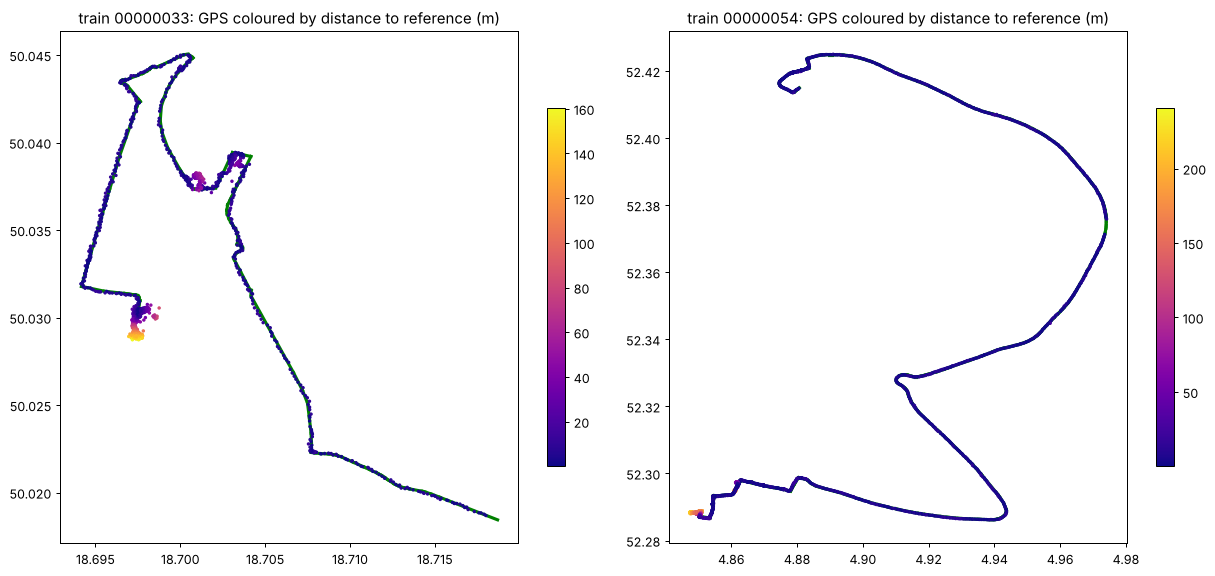

,trip,points,pct_over_100m,median_dist_m,median_offset_x_m,median_offset_y_m,route_length_km,gps_path_km
0,00000033,5844,51.0,122.4,0.1,122.2,6.4,47.8
1,00000054,19313,85.2,140.0,-9.2,-131.4,31.4,169.3


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
off_rows = []
for a, tid in zip(ax, ["00000033", "00000054"]):
    t = load_trip(os.path.join(RAW, "train", tid)); route = load_route(os.path.join(RAW, "train", tid))
    lab, ldist = labels[("train", tid)]
    nl = t.node_lonlat
    for e in route:
        u, v = t.arcs[e]; a.plot([nl[u, 0], nl[v, 0]], [nl[u, 1], nl[v, 1]], color="green", lw=2.5)
    sc = a.scatter(t.lonlat[:, 0], t.lonlat[:, 1], c=np.clip(ldist, 0, 300), cmap="plasma", s=3, zorder=3)
    a.set(title=f"train {tid}: GPS coloured by distance to reference (m)"); plt.colorbar(sc, ax=a, shrink=.7)
    # is it a constant shift? offset vector GPS -> projection on the labelled arc
    _, tt = t.point_arc_distance(t.xy, lab)
    proj = t.node_xy[t.arcs[lab, 0]] + tt[:, None] * (t.node_xy[t.arcs[lab, 1]] - t.node_xy[t.arcs[lab, 0]])
    off = proj - t.xy
    off_rows.append(dict(trip=tid, points=len(lab), pct_over_100m=100 * (ldist > 100).mean(),
                         median_dist_m=np.median(ldist), median_offset_x_m=np.median(off[:, 0]),
                         median_offset_y_m=np.median(off[:, 1]),
                         route_length_km=t.arc_len[route].sum() / 1000,
                         gps_path_km=np.hypot(*np.diff(t.xy, axis=0).T).sum() / 1000))
plt.tight_layout(); plt.savefig(os.path.join(FIG, "stage3_trips_33_54.png"), dpi=120); plt.show()
pd.DataFrame(off_rows).round(1)

In both trips large parts of the GPS track run far (100–250 m+) from the reference route, and
the reference's length does not match the distance the GPS actually covers, so the reference
does not describe the recorded drive for those stretches. **Decision:** exclude trips 33 and
54 from model training, and additionally drop any training point whose aligned label is more
than 100 m away. They stay in the inventory and EDA, and we state this limitation in the report.

## 9. Candidate generation
For each GPS point we need a short list of road arcs that could be the true one. Too few →
the true arc is missing (**candidate miss rate**, an upper bound on accuracy). Too many →
slower models and harder decisions. We compared strategies on the reliable labels
(label ≤ 100 m, trips 33/54 excluded), including our first iteration (fixed top-5 nearest,
no radius).

Spatial search: a KD-tree over points sampled every 10 m along every arc (arcs are straight
segments), then exact point-to-segment distance.

In [13]:
bad_trips = {"00000033", "00000054"}
cfgs = [("top-5 nearest, no radius (first iteration)", None, 5),
        ("30 m, k<=8", 30, 8), ("50 m, k<=5", 50, 5), ("50 m, k<=8 (chosen)", 50, 8),
        ("75 m, k<=8", 75, 8), ("100 m, k<=12", 100, 12)]
acc = {c[0]: dict(hit=0, n=0, cands=0, fb=0, hit_test=0, n_test=0) for c in cfgs}
twin = {p: dict(n=0, nearest_correct=0, nearest_is_reverse=0) for p in PARTS}
for part in PARTS:
    for tid in list_trips(os.path.join(RAW, part)):
        if tid in bad_trips:
            continue
        t = load_trip(os.path.join(RAW, part, tid)); lab, ldist = labels[(part, tid)]
        ok = ldist <= 100
        near = t.arcs_near(t.xy, 100.0)
        for i in np.flatnonzero(ok):
            arcs = near[i]
            if len(arcs):
                d, _ = t.point_arc_distance(np.repeat(t.xy[i][None], len(arcs), 0), arcs)
                o = np.argsort(d); arcs, d = arcs[o], d[o]
            nearest = arcs[0] if len(arcs) else t.nearest_arcs(t.xy[i], 1)[0]
            tw_ = twin[part]; tw_["n"] += 1; tw_["nearest_correct"] += int(nearest == lab[i])
            tw_["nearest_is_reverse"] += int(t.arcs[nearest, 0] == t.arcs[lab[i], 1] and t.arcs[nearest, 1] == t.arcs[lab[i], 0])
            for name, r, k in cfgs:
                if r is None:
                    sel = arcs[:k] if len(arcs) >= k else t.nearest_arcs(t.xy[i], k)
                    fb = 0
                else:
                    sel = arcs[d <= r][:k] if len(arcs) else arcs
                    fb = int(len(sel) == 0)
                    if fb:
                        sel = t.nearest_arcs(t.xy[i], 3)
                h = int(lab[i] in sel)
                s = acc[name]
                if part == "train":
                    s["hit"] += h; s["n"] += 1; s["cands"] += len(sel); s["fb"] += fb
                else:
                    s["hit_test"] += h; s["n_test"] += 1
cand_cmp = pd.DataFrame([dict(strategy=k, train_miss_rate_pct=100 * (1 - v["hit"] / v["n"]),
                              student_test_miss_rate_pct=100 * (1 - v["hit_test"] / v["n_test"]),
                              mean_candidates=v["cands"] / v["n"], fallback_pct=100 * v["fb"] / v["n"])
                         for k, v in acc.items()]).round(3)
cand_cmp.to_csv(os.path.join(RES, "stage4_candidate_strategy_comparison.csv"), index=False)
cand_cmp

,strategy,train_miss_rate_pct,student_test_miss_rate_pct,mean_candidates,fallback_pct
0,"top-5 nearest, no radius (first iteration)",1.647,1.745,4.970,0.000
1,"30 m, k<=8",0.942,0.444,4.586,1.453
2,"50 m, k<=5",1.712,1.781,4.140,0.637
3,"50 m, k<=8 (chosen)",0.677,0.334,5.669,0.637
4,"75 m, k<=8",0.613,0.303,6.371,0.188
5,"100 m, k<=12",0.276,0.073,9.207,0.000


**Decision: radius 50 m, at most 8 candidates, fallback to the 3 nearest arcs when nothing is
within 50 m** (so every observation always has candidates). It cuts the miss rate of our first
top-5 approach substantially while keeping about 6 candidates per point; a larger radius or k
gains little extra recall for many more (mostly wrong) candidates.

## 10. Direction twins
Two-way roads are stored as two arcs on the same nodes, one per direction, at **identical
distance** from any GPS point. Distance alone cannot separate them:

In [14]:
tw = pd.DataFrame(twin).T
tw["nearest_correct_pct"] = 100 * tw.nearest_correct / tw.n
tw["nearest_is_reverse_twin_pct"] = 100 * tw.nearest_is_reverse / tw.n
tw[["nearest_correct_pct", "nearest_is_reverse_twin_pct"]].round(1)

,nearest_correct_pct,nearest_is_reverse_twin_pct
train,56.6,31.7
student_test,55.0,34.2


Picking the nearest arc is right only about half the time, and in a large share of the errors
it is the same road in the opposite direction. Heading and context features (next section)
are therefore essential.

## 11. Feature engineering
Each row is one *(GPS observation, candidate arc)* pair; target `y = 1` if the candidate is the
observation's aligned reference arc. Everything below is computed from GPS + network only, so
the identical code runs at inference time in the API (no label information is used).

In [15]:
feature_doc = pd.DataFrame([
    ("dist", "geometry", "perpendicular distance GPS point → arc segment (m)"),
    ("dist_rank", "relative", "rank of the candidate by distance within the observation (0 = nearest)"),
    ("dist_minus_min", "relative", "distance minus the nearest candidate's distance (m)"),
    ("dist_ratio", "relative", "distance / (nearest candidate distance + 1)"),
    ("n_cands", "relative", "number of candidates of the observation (road density)"),
    ("head_diff", "direction", "angle between GPS heading (±2-point window) and arc bearing (0–180°)"),
    ("speed", "kinematics", "speed from the ±2-point window (m/s); tells the model when heading is unreliable"),
    ("move_dist", "kinematics", "distance moved over the ±2-point window (m)"),
    ("arc_len", "geometry", "arc length (m)"),
    ("t_proj", "geometry", "projection position along the arc (0 = start, 1 = end)"),
    ("end_dist", "geometry", "distance of the projection to the nearer arc end (m)"),
    ("has_reverse", "network", "1 if the arc has an opposite-direction twin (two-way road)"),
    ("ctx_dist_mean", "temporal context", "mean distance of observations i−3…i+3 to this arc (m)"),
    ("ctx_dist_max", "temporal context", "max distance of observations i−3…i+3 to this arc (m)"),
    ("ctx_head_diff", "temporal context", "mean heading difference over i−3…i+3"),
    ("dt_prev", "kinematics", "time since the previous observation (s)"),
    ("out_deg_to", "network", "out-degree of the arc's end node (junction complexity)"),
    ("in_deg_from", "network", "in-degree of the arc's start node"),
    ("trip_sigma", "noise model", "per-trip robust GPS noise scale = 1.4826·median(nearest distance) (m)"),
    ("dist_z", "noise model", "dist / trip_sigma"),
    ("ctx_dist_z", "noise model", "ctx_dist_mean / trip_sigma"),
    ("head_consistency", "temporal context", "share of i−3…i+3 whose heading agrees with the arc (<45°)"),
], columns=["feature", "group", "definition"])
assert list(feature_doc.feature) == FEATURES
feature_doc.to_csv(os.path.join(RES, "stage4_feature_dictionary.csv"), index=False)
print("candidate parameters:", DEFAULT_CAND)
feature_doc

candidate parameters: {'radius': 50.0, 'k_max': 8, 'k_fallback': 3, 'ctx': 3}


,feature,group,definition
0,dist,geometry,perpendicular distance GPS point → arc segment (m)
1,dist_rank,relative,rank of the candidate by distance within the observation (0 = nearest)
2,dist_minus_min,relative,distance minus the nearest candidate's distance (m)
3,dist_ratio,relative,distance / (nearest candidate distance + 1)
4,n_cands,relative,number of candidates of the observation (road density)
5,head_diff,direction,angle between GPS heading (±2-point window) and arc bearing (0–180°)
6,speed,kinematics,speed from the ±2-point window (m/s); tells the model when heading is unreliable
7,move_dist,kinematics,distance moved over the ±2-point window (m)
8,arc_len,geometry,arc length (m)
9,t_proj,geometry,"projection position along the arc (0 = start, 1 = end)"


In [16]:
frames = []
t0 = time.time()
for part in PARTS:
    for tid in list_trips(os.path.join(RAW, part)):
        t = load_trip(os.path.join(RAW, part, tid))
        lab, ldist = labels[(part, tid)]
        df = attach_labels(build_features(t, **DEFAULT_CAND), lab, ldist)
        df["partition"] = part
        frames.append(df)
cand = pd.concat(frames, ignore_index=True)
print(f"built {len(cand):,} candidate rows for {cand.groupby(['partition', 'trip']).ngroups} trips in {time.time() - t0:.0f} s")
pd.DataFrame({"candidate_rows": cand.groupby("partition").size(),
              "observations": cand.groupby(["partition", "trip"]).pt.nunique().groupby("partition").sum(),
              "positive_rate": cand.groupby("partition").y.mean().round(4)})

built 1,253,421 candidate rows for 90 trips in 34 s


,candidate_rows,observations,positive_rate
partition,,,
student_test,113694,19160,0.1678
train,1139727,208417,0.1623


### Evidence for the features
(a) **Single-feature AUC** on the train partition (reliable labels): how well each feature on
its own separates true from wrong candidates (0.5 = useless; values below 0.5 mean "lower is
better", so we report max(AUC, 1−AUC)).

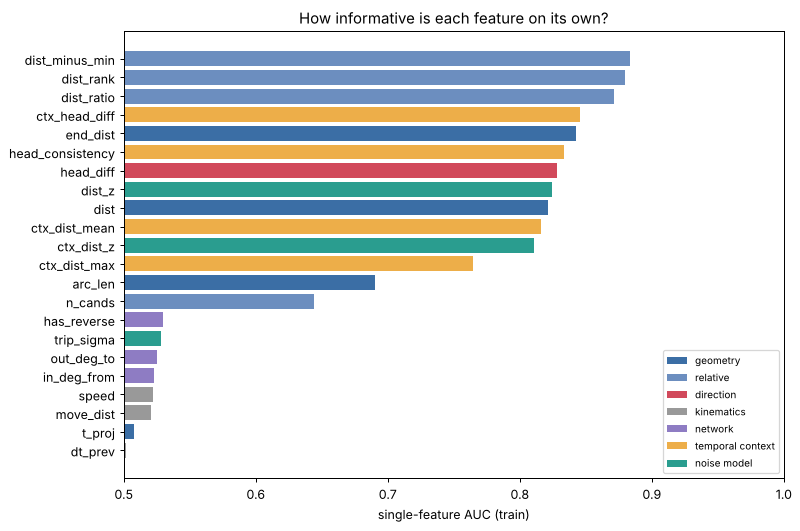

In [17]:
trn = cand[(cand.partition == "train") & (~cand.trip.isin(bad_trips)) & (cand.label_ok == 1)]
auc = pd.DataFrame([(f, feature_doc.set_index("feature").group[f], max(a, 1 - a))
                    for f in FEATURES for a in [roc_auc_score(trn.y, trn[f].fillna(0))]],
                   columns=["feature", "group", "auc"]).sort_values("auc", ascending=False)
auc.to_csv(os.path.join(RES, "stage4_feature_auc.csv"), index=False)
fig, ax = plt.subplots(figsize=(9, 6))
cols = {"geometry": "#3b6ea5", "relative": "#6c8ebf", "direction": "#d1495b", "kinematics": "#999999",
        "network": "#8e7cc3", "temporal context": "#edae49", "noise model": "#2a9d8f"}
ax.barh(auc.feature, auc.auc, color=[cols[g] for g in auc.group]); ax.invert_yaxis()
ax.set(xlim=(0.5, 1.0), xlabel="single-feature AUC (train)", title="How informative is each feature on its own?")
for g, c in cols.items():
    ax.barh([0], [0], color=c, label=g)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "stage4_feature_auc.png"), dpi=120); plt.show()

(b) **Why a windowed heading?** Compare the heading error *on the true arc* when heading comes
from one 1-s step (first iteration) versus our ±2-point window, split by speed:

In [18]:
hrows = []
for part in PARTS:
    for tid in list_trips(os.path.join(RAW, part)):
        if tid in bad_trips:
            continue
        t = load_trip(os.path.join(RAW, part, tid)); lab, ldist = labels[(part, tid)]
        ok = ldist <= 100
        h_win, spd, _ = gps_heading_speed(t.xy, t.t, win=2)
        d1 = np.diff(t.xy, axis=0, prepend=t.xy[:1])
        h_step = (np.degrees(np.arctan2(d1[:, 0], d1[:, 1])) + 360) % 360
        hrows.append(pd.DataFrame(dict(speed=spd[ok], err_step=angle_diff(h_step, t.arc_bearing[lab])[ok],
                                       err_window=angle_diff(h_win, t.arc_bearing[lab])[ok])))
hd = pd.concat(hrows)
hd["speed_band"] = pd.cut(hd.speed, [-0.1, 1, 3, 8, 15, 100], labels=["<1 m/s", "1-3", "3-8", "8-15", ">15"])
htab = hd.groupby("speed_band", observed=True).agg(points=("speed", "size"),
                                                   median_err_1s_step=("err_step", "median"),
                                                   median_err_window=("err_window", "median"),
                                                   pct_wrong_dir_1s_step=("err_step", lambda s: 100 * (s > 90).mean()))
htab["pct_wrong_dir_window"] = hd.groupby("speed_band", observed=True).err_window.apply(lambda s: 100 * (s > 90).mean())
htab.round(1)

,points,median_err_1s_step,median_err_window,pct_wrong_dir_1s_step,pct_wrong_dir_window
speed_band,,,,,
<1 m/s,7661,82.5,75.9,45.8,42.3
1-3,31632,75.4,50.6,42.1,30.0
3-8,53089,45.5,15.2,24.2,6.2
8-15,45763,20.7,6.0,4.3,0.2
>15,63149,10.1,2.9,0.3,0.0


At low speed a single 1-s step is dominated by GPS jitter, so heading often points the wrong
way (>90° off the true arc); the window reduces this, and passing `speed` lets the classifier
learn when to trust heading at all.

(c) **Distributions of key features for true vs other candidates** (train):

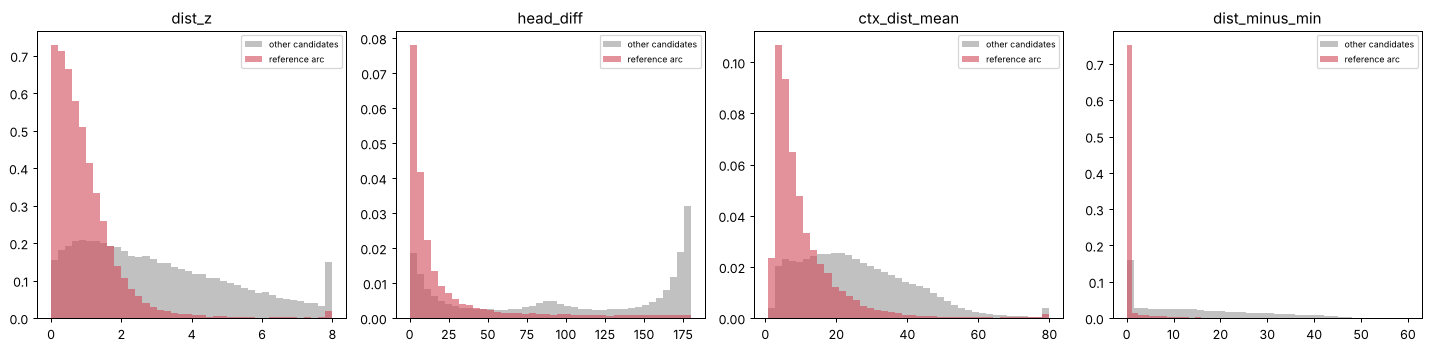

In [19]:
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
smp = trn.sample(200000, random_state=SEED)
for a, f, lim in zip(ax, ["dist_z", "head_diff", "ctx_dist_mean", "dist_minus_min"], [8, 180, 80, 60]):
    a.hist(smp.loc[smp.y == 0, f].clip(upper=lim), bins=40, alpha=.6, density=True, label="other candidates", color="#999999")
    a.hist(smp.loc[smp.y == 1, f].clip(upper=lim), bins=40, alpha=.6, density=True, label="reference arc", color="#d1495b")
    a.set(title=f); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "stage4_feature_distributions.png"), dpi=120); plt.show()

(d) **Train vs student_test shift.** The noise scale differs between partitions, which is why
the per-trip noise features exist:

In [20]:
cand.groupby(["partition", "trip"]).trip_sigma.first().groupby("partition").describe().round(2)

,count,mean,std,min,25%,50%,75%,max
partition,,,,,,,,
student_test,10.0,6.73,1.31,4.94,5.95,6.39,7.96,8.62
train,80.0,7.35,8.35,3.76,5.50,6.12,6.85,80.00


## 12. Group-aware folds
Consecutive GPS points are almost identical, so a random row split would leak information.
All rows of a trip go to the same fold (GroupKFold, 5 folds, groups = trip); student_test is
never part of a fold.

In [21]:
tr_rows = cand[(cand.partition == "train") & (~cand.trip.isin(bad_trips))]
folds = np.full(len(tr_rows), -1)
for k, (_, b) in enumerate(GroupKFold(n_splits=5).split(tr_rows, groups=tr_rows.trip)):
    folds[b] = k
fa = pd.DataFrame({"trip": tr_rows.trip.values, "fold": folds}).drop_duplicates()
assert fa.trip.is_unique, "a trip appears in more than one fold"
fa.to_csv(os.path.join(RES, "stage4_cv_fold_assignment.csv"), index=False)
fa.merge(inv[["trip", "gps_points"]].drop_duplicates("trip"), on="trip").groupby("fold").agg(
    trips=("trip", "size"), gps_points=("gps_points", "sum"))

,trips,gps_points
fold,,
0,15,37990
1,15,31969
2,16,41816
3,16,34095
4,16,37390


## 13. Saved outputs
The candidate table is ~1.25 M rows. It is saved as compressed pickles in `data/processed/`
(git-ignored and regenerable, instead of a 200 MB+ CSV that GitHub would reject); small
summaries go to `results/`.

In [22]:
for part in PARTS:
    cand[cand.partition == part].reset_index(drop=True).to_pickle(os.path.join(PROC, f"{part}.pkl"))
cs = cand.groupby("partition").apply(lambda g: pd.Series(dict(
    trips=g.trip.nunique(), observations=g.groupby("trip").pt.nunique().sum(), candidate_rows=len(g),
    mean_candidates=len(g) / g.groupby("trip").pt.nunique().sum(),
    candidate_miss_rate_pct=100 * (1 - g.groupby(["trip", "pt"]).y.max().mean()),
    miss_rate_reliable_labels_pct=100 * (1 - g[(g.label_ok == 1) & ~g.trip.isin(bad_trips)].groupby(["trip", "pt"]).y.max().mean()),
    fallback_pct=100 * g.groupby(["trip", "pt"]).fallback.max().mean(),
    positive_rate=g.y.mean())), include_groups=False).round(3)
cs.to_csv(os.path.join(RES, "stage4_candidate_summary.csv"))
for f in sorted(os.listdir(RES)):
    if f.startswith("stage"):
        print("results/" + f)
cs

results/stage2_data_quality_report.csv
results/stage2_inventory.csv
results/stage2_large_gaps.csv
results/stage2_network_connectivity.csv
results/stage2_route_breaks.csv
results/stage3_label_quality.csv
results/stage4_candidate_strategy_comparison.csv
results/stage4_candidate_summary.csv
results/stage4_cv_fold_assignment.csv
results/stage4_feature_auc.csv
results/stage4_feature_dictionary.csv
results/stage_2_3_4


,trips,observations,candidate_rows,mean_candidates,candidate_miss_rate_pct,miss_rate_reliable_labels_pct,fallback_pct,positive_rate
partition,,,,,,,,
student_test,10.0,19160.0,113694.0,5.934,0.423,0.334,0.000,0.168
train,80.0,208417.0,1139727.0,5.468,11.231,0.677,8.746,0.162


## 14. Data-quality decision log

In [23]:
log = pd.DataFrame([
    ("Coordinates are angles; trips in many countries (35°S–62°N)",
     "Distances must be metric and locally accurate",
     "Per-trip local equirectangular projection (validated against haversine, section 6)"),
    ("No missing / invalid values, timestamps monotonic (train, student_test)",
     "Evaluator files could still contain bad rows",
     "Cleaning rules kept in load_trip(): drop NaN, out-of-range, non-increasing timestamps"),
    ("Repeated identical GPS fixes (vehicle stopped)",
     "They are real observations; heading is undefined there",
     "Keep them; windowed heading + speed feature so the model can discount heading"),
    ("Long time gaps (up to ~42 h in train 90, ~15 h in train 78) with little movement",
     "Parking pauses inside one trip, not separate drives",
     "Keep trips whole; HMM relaxes transitions with the time gap"),
    ("Broken reference routes (consecutive route arcs not connected) in 11 trips",
     "Reference skips short links; GPS is continuous",
     "Keep trips; ordered alignment confines the effect to points near the break; report reference continuity"),
    ("Route is an ordered arc list, not per-point labels",
     "Vehicle never moves backwards along its own route",
     "Monotonic DP alignment for per-point labels (section 8)"),
    ("Trips 33 and 54: most GPS points >100 m from the reference",
     "Reference does not describe those stretches",
     "Exclude both from training; drop any training point with label distance >100 m"),
    ("Road networks fragmented into many weak components",
     "Clipping around each trip; the route lies in the largest component",
     "Keep full network; HMM gives disconnected pairs a finite penalty"),
    ("~90% of arcs have a reverse twin at identical distance",
     "Distance alone cannot choose the direction",
     "Heading, context and network features; HMM transitions penalise U-turns"),
    ("Fixed top-5 candidates missed the true arc too often and admitted arcs >1 km away",
     "True arc almost always within 50 m",
     "50 m radius, k<=8, fallback to 3 nearest (section 9)"),
    ("Train noisier than student_test",
     "Noise level varies per trip",
     "Per-trip robust noise scale and noise-normalised distance features"),
    ("Candidate table is too large for GitHub as CSV",
     "Outputs must be reproducible",
     "Save as git-ignored pickles; commit the code that regenerates them"),
], columns=["issue", "assumption", "decision"])
log.to_csv(os.path.join(RES, "stage2_data_quality_log.csv"), index=False)
log

,issue,assumption,decision
0,Coordinates are angles; trips in many countries (35°S–62°N),Distances must be metric and locally accurate,"Per-trip local equirectangular projection (validated against haversine, section 6)"
1,"No missing / invalid values, timestamps monotonic (train, student_test)",Evaluator files could still contain bad rows,"Cleaning rules kept in load_trip(): drop NaN, out-of-range, non-increasing timestamps"
2,Repeated identical GPS fixes (vehicle stopped),They are real observations; heading is undefined there,Keep them; windowed heading + speed feature so the model can discount heading
3,"Long time gaps (up to ~42 h in train 90, ~15 h in train 78) with little movement","Parking pauses inside one trip, not separate drives",Keep trips whole; HMM relaxes transitions with the time gap
4,Broken reference routes (consecutive route arcs not connected) in 11 trips,Reference skips short links; GPS is continuous,Keep trips; ordered alignment confines the effect to points near the break; report reference continuity
5,"Route is an ordered arc list, not per-point labels",Vehicle never moves backwards along its own route,Monotonic DP alignment for per-point labels (section 8)
6,Trips 33 and 54: most GPS points >100 m from the reference,Reference does not describe those stretches,Exclude both from training; drop any training point with label distance >100 m
7,Road networks fragmented into many weak components,Clipping around each trip; the route lies in the largest component,Keep full network; HMM gives disconnected pairs a finite penalty
8,~90% of arcs have a reverse twin at identical distance,Distance alone cannot choose the direction,"Heading, context and network features; HMM transitions penalise U-turns"
9,Fixed top-5 candidates missed the true arc too often and admitted arcs >1 km away,True arc almost always within 50 m,"50 m radius, k<=8, fallback to 3 nearest (section 9)"


## 15. Folium maps (GPS, road network, reference route, route breaks)
Requires `pip install folium`. Maps are written to `maps/` and open in any browser.

In [24]:
try:
    import folium

    def eda_map(part, tid):
        t = load_trip(os.path.join(RAW, part, tid)); route = load_route(os.path.join(RAW, part, tid))
        nl = t.node_lonlat
        lo, hi = t.lonlat.min(0) - .002, t.lonlat.max(0) + .002
        m = folium.Map(location=[t.lonlat[:, 1].mean(), t.lonlat[:, 0].mean()], zoom_start=14, tiles=None)
        folium.TileLayer("https://{s}.basemaps.cartocdn.com/rastertiles/voyager/{z}/{x}/{y}{r}.png",
                         attr="&copy; OpenStreetMap &copy; CARTO", name="Basemap (English labels)", subdomains="abcd").add_to(m)
        fg_net = folium.FeatureGroup("Road network (dataset)", show=False)
        a0 = nl[t.arcs[:, 0]]; near = np.flatnonzero(((a0 >= lo) & (a0 <= hi)).all(1))[:20000]
        for e in near:
            u, v = t.arcs[e]; folium.PolyLine([(nl[u, 1], nl[u, 0]), (nl[v, 1], nl[v, 0])], color="#888", weight=1).add_to(fg_net)
        fg_ref = folium.FeatureGroup("Reference route (green)")
        for e in route:
            u, v = t.arcs[e]; folium.PolyLine([(nl[u, 1], nl[u, 0]), (nl[v, 1], nl[v, 0])], color="green", weight=5, opacity=.7).add_to(fg_ref)
        fg_gps = folium.FeatureGroup("GPS observations (blue)")
        for lon, lat in t.lonlat[::2]:
            folium.CircleMarker([lat, lon], radius=2, color="blue", weight=0, fill=True, fill_opacity=.8).add_to(fg_gps)
        fg_brk = folium.FeatureGroup("Reference-route breaks (red)")
        for _, b in breaks[(breaks.partition == part) & (breaks.trip == tid)].iterrows():
            folium.CircleMarker([b.lat, b.lon], radius=10, color="red", weight=3,
                                tooltip=f"route break: {b.gap_between_arcs_m:.0f} m gap").add_to(fg_brk)
        for fg in (fg_net, fg_ref, fg_gps, fg_brk):
            fg.add_to(m)
        legend = (f"<div style='position:fixed;bottom:20px;left:20px;z-index:9999;background:white;padding:8px;"
                  f"border:1px solid #999;font:12px sans-serif'><b>Team 111 · {part} {tid}</b><br>"
                  "<span style='color:blue'>&#9679;</span> GPS &nbsp;<span style='color:green'>&#9644;</span> reference route"
                  " &nbsp;<span style='color:red'>&#9711;</span> route break &nbsp;<span style='color:#888'>&#9644;</span> network</div>")
        m.get_root().html.add_child(folium.Element(legend))
        folium.LayerControl(collapsed=False).add_to(m); m.fit_bounds([[lo[1], lo[0]], [hi[1], hi[0]]])
        out = os.path.join(MAPS, f"eda_{part}_{tid}.html"); m.save(out); return out

    for part, tid in [("train", "00000046"), ("train", "00000075"), ("student_test", "00000076"), ("train", "00000054")]:
        print("saved", eda_map(part, tid))
except ImportError:
    print("folium is not installed in this environment -> run `pip install folium` and re-run this cell")

folium is not installed in this environment -> run `pip install folium` and re-run this cell
